In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
tumor = "t46"
tumor_variants = pd.read_csv(f"../data/{tumor}/{tumor}.tumor_spec_variant_counts.txt", sep = "\t")

In [3]:
A_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_A_WGS_bins.txt", sep="\t")

In [4]:
normal_info = A_df[["population", "normal_population"]].drop_duplicates()
normal_A = normal_info[normal_info["normal_population"] == True]["population"].values[0]

In [5]:
A_dict = {}
for cluster in A_df['population'].unique():
    print(cluster)
    cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
    A_dict[cluster] = {
        'cells': cells_in_cluster
    }

A1
A2111
A211211
A211212
A21122
A21211
A21212
A21221
A21222
A22


In [6]:
tumor_variants = tumor_variants[tumor_variants["alt_count"]>0]

In [7]:
len(tumor_variants)

38476

In [8]:
tumor_variants["chrom"].unique()

array(['chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr21', 'chr15',
       'chr16', 'chr17', 'chr7', 'chr18', 'chr19', 'chr1', 'chr20',
       'chr22', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr8', 'chr9',
       'chrM', 'chrX', 'chrY'], dtype=object)

In [9]:
chrom_set = ["chr"+str(i) for i in range(1,23)] + ["chrX"]

In [10]:
pop_var_dict = {}
tot_var_dict = {}
for pop in A_dict.keys():
    pop_var_dict[pop] = {}
    tot_var_dict[pop] = 0
for ch in chrom_set:
    ch_var = tumor_variants[tumor_variants['chrom'] == ch]
    for pop in A_dict.keys():
        pop_cells = A_dict[pop]['cells']
        pop_ch_var = ch_var[ch_var['cell_id'].isin(pop_cells)]
        cells_with_var = pop_ch_var['cell_id'].unique()
        pop_var = pop_ch_var["pos"].unique()
        pop_var_dict[pop][ch] = pop_var
        tot_var_dict[pop] += len(pop_var)
    #print(pop,len(cells_with_var), len(cells_with_var)/len(pop_cells))

In [11]:
# variants per cell in each cluster
for pop in tot_var_dict:
    print(pop, tot_var_dict[pop]/len(A_dict[pop]['cells']))

A1 0.8250950570342205
A2111 24.516129032258064
A211211 21.763157894736842
A211212 18.472972972972972
A21122 21.514285714285716
A21211 23.275862068965516
A21212 16.047619047619047
A21221 18.508196721311474
A21222 19.664233576642335
A22 11.202959830866808


In [12]:
#pop_var_dict

In [13]:
tumor_variants = pd.read_csv(f"../data/{tumor}/{tumor}.tumor_spec_pseudo_variants.txt", sep = "\t")

In [14]:
tumor_variants = tumor_variants[tumor_variants["alt_count"]>0]

In [15]:
len(tumor_variants)

221

In [16]:
pop_var_dict = {}
tot_var_dict = {}
for pop in A_dict.keys():
    pop_var_dict[pop] = {}
    tot_var_dict[pop] = 0
for ch in chrom_set:
    ch_var = tumor_variants[tumor_variants['chrom'] == ch]
    for pop in A_dict.keys():
        pop_cells = A_dict[pop]['cells']
        pop_ch_var = ch_var[ch_var['cell_id'].isin(pop_cells)]
        cells_with_var = pop_ch_var['cell_id'].unique()
        pop_var = pop_ch_var["pos"].unique()
        pop_var_dict[pop][ch] = pop_var
        tot_var_dict[pop] += len(pop_var)
    #print(pop,len(cells_with_var), len(cells_with_var)/len(pop_cells))

In [17]:
# pseudo variants per cell in each cluster
for pop in tot_var_dict:
    print(pop, tot_var_dict[pop]/len(A_dict[pop]['cells']))

A1 0.07984790874524715
A2111 0.12903225806451613
A211211 0.09210526315789473
A211212 0.12162162162162163
A21122 0.11428571428571428
A21211 0.13793103448275862
A21212 0.08465608465608465
A21221 0.13114754098360656
A21222 0.072992700729927
A22 0.09090909090909091


In [18]:
# First, load the real variants
tumor_variants_real = pd.read_csv(f"../data/{tumor}/{tumor}.tumor_spec_variant_counts.txt", sep="\t")
#tumor_variants_real = tumor_variants_real[tumor_variants_real["alt_count"] > 0]

# Then load pseudo variants
tumor_variants_pseudo = pd.read_csv(f"../data/{tumor}/{tumor}.tumor_spec_pseudo_variants.txt", sep="\t")
#tumor_variants_pseudo = tumor_variants_pseudo[tumor_variants_pseudo["alt_count"] > 0]


In [19]:
# Initialize lists to store data
pop_names = []
opportunities_for_variants = []
opportunities_for_pseudo = []
num_variant_positions = []
num_cells_with_variants = []
variants_per_cell = []
num_pseudo_positions = []
num_cells_with_pseudo = []
pseudo_per_cell = []
Num_cells = []
# For each population, compute all metrics
for pop in A_dict.keys():
    if pop == normal_A:
        pop_names.append(pop+" (normal)")
    else:
        pop_names.append(pop)
    pop_cells = A_dict[pop]['cells']
    num_cells = len(pop_cells)
    Num_cells.append(num_cells)
    
    # Real variants
    pop_real_variants = tumor_variants_real[tumor_variants_real['cell_id'].isin(pop_cells)]
    opportunities_for_variants.append(len(pop_real_variants))
    pop_real_variants = pop_real_variants[pop_real_variants["alt_count"] > 0]
    num_variant_positions.append(len(pop_real_variants))
    num_cells_with_variants.append(len(pop_real_variants['cell_id'].unique()))
    variants_per_cell.append(len(pop_real_variants) / num_cells)
    
    # Pseudo variants
    pop_pseudo_variants = tumor_variants_pseudo[tumor_variants_pseudo['cell_id'].isin(pop_cells)]
    opportunities_for_pseudo.append(len(pop_pseudo_variants))
    pop_pseudo_variants = pop_pseudo_variants[pop_pseudo_variants["alt_count"] > 0]
    num_pseudo_positions.append(len(pop_pseudo_variants))
    num_cells_with_pseudo.append(len(pop_pseudo_variants['cell_id'].unique()))
    pseudo_per_cell.append(len(pop_pseudo_variants) / num_cells)


In [20]:
# Create the summary table
variant_summary = pd.DataFrame({
    'Population': pop_names,
    'Num_Cells': Num_cells,
    'opportunities_for_variants': opportunities_for_variants,
    'variant_observed': num_variant_positions,
    'Cells_With_Variants': num_cells_with_variants,
    'opportunities_for_pseudo': opportunities_for_pseudo,
    'pseudo_variant_observed': num_pseudo_positions,
    'Cells_With_Pseudo_variants': num_cells_with_pseudo
})

In [21]:
variant_summary

,Population,Num_Cells,opportunities_for_variants,variant_observed,Cells_With_Variants,opportunities_for_pseudo,pseudo_variant_observed,Cells_With_Pseudo_variants
0,A1 (normal),263,18835,326,153,18829,23,23
1,A2111,31,3440,834,31,3508,4,4
2,A211211,76,7746,1958,76,8020,7,7
3,A211212,74,6694,1587,74,6775,9,9
4,A21122,35,3312,818,35,3336,4,4
5,A21211,29,2749,741,29,2861,4,4
6,A21212,189,16703,4033,189,17010,23,21
7,A21221,61,5075,1267,61,5079,8,6
8,A21222,137,13909,3443,137,14055,13,13
9,A22,473,37426,8834,473,38143,49,45


In [22]:
variant_summary["variant_frequency"] = variant_summary["variant_observed"]/variant_summary["opportunities_for_variants"]
variant_summary["pseudo_frequency"] = variant_summary["pseudo_variant_observed"]/variant_summary["opportunities_for_pseudo"]
variant_summary["variant_per_cell"] = variant_summary["variant_observed"]/variant_summary["Num_Cells"]
variant_summary["pseudo_per_cell"] = variant_summary["pseudo_variant_observed"]/variant_summary["Num_Cells"]


In [23]:
variant_summary

,Population,Num_Cells,opportunities_for_variants,variant_observed,Cells_With_Variants,opportunities_for_pseudo,pseudo_variant_observed,Cells_With_Pseudo_variants,variant_frequency,pseudo_frequency,variant_per_cell,pseudo_per_cell
0,A1 (normal),263,18835,326,153,18829,23,23,0.017308,0.001222,1.239544,0.087452
1,A2111,31,3440,834,31,3508,4,4,0.242442,0.001140,26.903226,0.129032
2,A211211,76,7746,1958,76,8020,7,7,0.252776,0.000873,25.763158,0.092105
3,A211212,74,6694,1587,74,6775,9,9,0.237078,0.001328,21.445946,0.121622
4,A21122,35,3312,818,35,3336,4,4,0.246981,0.001199,23.371429,0.114286
5,A21211,29,2749,741,29,2861,4,4,0.269553,0.001398,25.551724,0.137931
6,A21212,189,16703,4033,189,17010,23,21,0.241454,0.001352,21.338624,0.121693
7,A21221,61,5075,1267,61,5079,8,6,0.249655,0.001575,20.770492,0.131148
8,A21222,137,13909,3443,137,14055,13,13,0.247538,0.000925,25.131387,0.094891
9,A22,473,37426,8834,473,38143,49,45,0.236039,0.001285,18.676533,0.103594


In [24]:
tumor_variants_real.head()

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
0,chr10,103683,AAAACCAAAGTAGTTCT,0,0,0,1,1,0,1
1,chr10,103683,TTGCGTTTTACGTTATT,0,1,0,0,0,1,1
2,chr10,103683,TAGTCAGGTGACAATAT,0,0,0,1,1,0,1
3,chr10,103683,GAGATAAGCCTCACTCT,0,1,0,0,0,1,1
4,chr10,103683,ACGGGAAAGGCCTGTCC,0,0,0,1,1,0,1


In [25]:
tumor_info = tumor_variants_real[~tumor_variants_real["cell_id"].isin(A_dict[normal_A]["cells"])]

In [26]:
pos_groups = tumor_info.groupby(["chrom", "pos"])

In [27]:
tumor_info

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
1,chr10,103683,TTGCGTTTTACGTTATT,0,1,0,0,0,1,1
2,chr10,103683,TAGTCAGGTGACAATAT,0,0,0,1,1,0,1
3,chr10,103683,GAGATAAGCCTCACTCT,0,1,0,0,0,1,1
4,chr10,103683,ACGGGAAAGGCCTGTCC,0,0,0,1,1,0,1
5,chr10,103683,GACACGTGCAGGTCTGT,0,0,0,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...
178527,chrY,59000895,AATGAGAACCGAACACA,0,0,2,0,2,0,2
178528,chrY,59000895,CAAATTCGACTTTCTGT,0,0,1,0,1,0,1
178531,chrY,59000895,TAAACTGAACCCCGTGA,0,0,1,0,1,0,1
178532,chrY,59000895,GCATCGGAACAATCTCG,0,0,1,0,1,0,1


In [28]:
# List all unique (chrom, pos) combinations
unique_positions = tumor_info[["chrom", "pos"]].drop_duplicates().values.tolist()

In [29]:
p = unique_positions[0]
df = pos_groups.get_group((p[0], p[1]))


In [30]:
row_list = []
for p in unique_positions:
    df = pos_groups.get_group((p[0], p[1]))
    r_count = df["ref_count"].sum()
    a_count = df["alt_count"].sum()
    tot = r_count + a_count
    row_list.append({
        "chrom": p[0],
        "pos": p[1],
        "ref_count": r_count,
        "alt_count": a_count,
        "total_count": tot,
        "variant_frequency": a_count / tot
    })

tumor_variant_summary = pd.DataFrame(row_list)

/var/folders/p3/qk0s0_l96v7679y441dyvbx80000gn/T/ipykernel_6302/3236079474.py:13: RuntimeWarning: invalid value encountered in scalar divide
  "variant_frequency": a_count / tot


<Axes: >

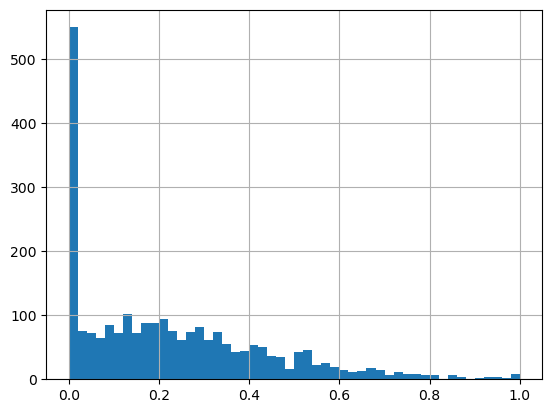

In [36]:
tumor_variant_summary[tumor_variant_summary["total_count"] > 20]["variant_frequency"].hist(bins=50) 

<Axes: >

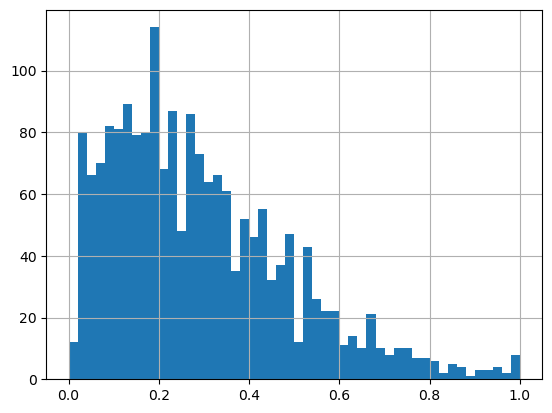

In [37]:
tumor_variant_summary[(tumor_variant_summary["variant_frequency"]!=0) & (tumor_variant_summary["total_count"] > 20)]["variant_frequency"].hist(bins=50)